# 03 · Profitability
**Where to Invest: Microsoft Growth Investment Analysis**

Goal: decide which product lines and sales regions get more investment. Each one is placed on
growth × operating margin (FY26) and gets an action: invest, optimise, maintain or deprioritise.

Tools: SQL (DuckDB) to build the star schema and run the KPI views; Python (pandas) to read the
results; matplotlib / seaborn for the charts.

> **Synthetic data, calibrated to Microsoft's published results.** Generated by `data/generate.py`:
> totals by segment and quarter are close to Microsoft's reported figures; every record underneath
> them is invented.

In [1]:
import os, duckdb
from pathlib import Path
import pandas as pd

# Works whether the notebook is run from the project root or from notebooks/

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

con = duckdb.connect("data/finance.duckdb")
checks = con.execute(open("sql/01_build_star_schema.sql", encoding="utf-8").read()).df()
checks

,check_name,value
0,fact_billing rows,306684
1,fact_gl_cost rows,118481
2,fact_datacenter rows,1122
3,fact_opportunity rows,41612
4,problems: billing without customer,0
5,problems: billing without product,0
6,problems: billing month not in dim_date,0
7,problems: GL month not in dim_date,0
8,problems: datacenter region not in dimension,0
9,problems: opportunity without country,0


In [2]:
con.execute(open("sql/02_analysis_kpis.sql", encoding="utf-8").read())
kpi_quarter = con.sql("SELECT * FROM v_kpi_quarter").df()

ratio_columns = ["gross_margin","operating_margin","revenue_growth_yoy","lease_share_of_capex"]

kpi_quarter.style.format({
    **{
        column: lambda value: f"${value / 1_000_000_000:,.1f}B"
        for column in kpi_quarter.columns
        if column.endswith("_usd")
    },
    **{
        column: "{:.1%}"
        for column in ratio_columns
        if column in kpi_quarter.columns
    },
    "quarter_start": lambda value: value.strftime("%Y-%m-%d")
}, na_rep="—")

,fiscal_year_quarter,quarter_start,revenue_usd,gross_profit_usd,operating_income_usd,depreciation_usd,capex_usd,capex_finance_lease_usd,budget_revenue_usd,budget_operating_income_usd,gross_margin,operating_margin,revenue_growth_yoy,lease_share_of_capex,free_cash_flow_usd,revenue_vs_budget_usd,operating_income_vs_budget_usd
0,FY24-Q3,2024-01-01,$61.6B,$43.7B,$26.5B,$2.8B,$14.0B,$6.0B,—,—,70.9%,42.9%,—,43.0%,$15.2B,—,—
1,FY24-Q4,2024-04-01,$64.3B,$45.8B,$28.3B,$3.0B,$19.0B,$7.8B,—,—,71.1%,44.0%,—,41.0%,$12.2B,—,—
2,FY25-Q1,2024-07-01,$65.3B,$46.1B,$29.1B,$3.3B,$20.0B,$6.8B,$63.5B,$28.7B,70.6%,44.6%,—,33.9%,$12.4B,$1.8B,$0.4B
3,FY25-Q2,2024-10-01,$69.2B,$48.5B,$31.6B,$3.6B,$22.6B,$5.8B,$67.6B,$31.2B,70.0%,45.7%,—,25.6%,$12.7B,$1.7B,$0.5B
4,FY25-Q3,2025-01-01,$69.7B,$48.3B,$32.3B,$4.3B,$21.4B,$5.9B,$68.4B,$32.1B,69.3%,46.3%,13.1%,27.3%,$15.2B,$1.3B,$0.2B
5,FY25-Q4,2025-04-01,$76.2B,$53.1B,$36.0B,$5.0B,$24.2B,$9.2B,$74.4B,$35.0B,69.7%,47.3%,18.5%,38.0%,$16.8B,$1.8B,$1.0B
6,FY26-Q1,2025-07-01,$77.3B,$53.0B,$36.0B,$5.7B,$34.9B,$13.1B,$76.7B,$36.4B,68.5%,46.5%,18.4%,37.6%,$6.7B,$0.6B,$-0.5B
7,FY26-Q2,2025-10-01,$80.9B,$55.3B,$38.0B,$6.3B,$37.5B,$12.2B,$80.8B,$39.0B,68.4%,47.0%,16.9%,32.6%,$6.8B,$0.2B,$-1.0B
8,FY26-Q3,2026-01-01,$82.6B,$56.3B,$39.1B,$7.3B,$37.5B,$12.7B,$82.5B,$39.9B,68.2%,47.3%,18.4%,33.9%,$8.8B,$0.0B,$-0.8B
9,FY26-Q4,2026-04-01,$89.7B,$60.8B,$43.2B,$8.3B,$46.0B,$16.0B,$90.1B,$44.1B,67.8%,48.1%,17.6%,34.9%,$5.4B,$-0.5B,$-1.0B


## 1. Profitability by segment
How do revenue and operating margin compare across the three segments? Only **full fiscal years**
are compared: FY24 (Jan–Jun 2024, 6 months) and FY27 (Jul–Sep 2026, 3 months) are partial, so the
comparison is FY25 vs FY26. Segments are restated: Windows Commercial sits in Productivity and
Business Processes in both years.

In [3]:
# Segment P&L for the two full fiscal years
segments = con.sql("""
    SELECT fiscal_year, segment, revenue_usd, operating_income_usd, gross_margin, operating_margin
    FROM v_profitability_segment_fy
    WHERE fiscal_year IN ('FY25', 'FY26')
    ORDER BY segment, fiscal_year
""").df()

# One row per segment, FY25 and FY26 side by side
seg_fy = segments.pivot(index="segment", columns="fiscal_year",
                        values=["revenue_usd", "operating_income_usd", "operating_margin"])
seg_fy.columns = [f"{metric}_{fy.lower()}" for metric, fy in seg_fy.columns]
seg_fy["revenue_growth"] = seg_fy["revenue_usd_fy26"] / seg_fy["revenue_usd_fy25"] - 1
seg_fy["margin_change_pts"] = (seg_fy["operating_margin_fy26"] - seg_fy["operating_margin_fy25"]) * 100
seg_fy = seg_fy.sort_values("revenue_usd_fy26", ascending=False)

seg_fy.style.format({
    **{c: lambda v: f"${v / 1_000_000_000:,.1f}B" for c in seg_fy.columns if c.endswith(("_fy25", "_fy26")) and "usd" in c},
    **{c: "{:.1%}" for c in seg_fy.columns if c.startswith("operating_margin")},
    "revenue_growth": "{:+.1%}",
    "margin_change_pts": "{:+.1f} pts",
})

,revenue_usd_fy25,revenue_usd_fy26,operating_income_usd_fy25,operating_income_usd_fy26,operating_margin_fy25,operating_margin_fy26,revenue_growth,margin_change_pts
segment,,,,,,,,
Productivity and Business Processes,$120.1B,$139.4B,$69.4B,$84.2B,57.8%,60.4%,+16.1%,+2.6 pts
Intelligent Cloud,$105.8B,$137.2B,$47.3B,$57.4B,44.7%,41.8%,+29.7%,-2.8 pts
More Personal Computing,$54.6B,$53.9B,$12.4B,$14.6B,22.8%,27.2%,-1.3%,+4.4 pts


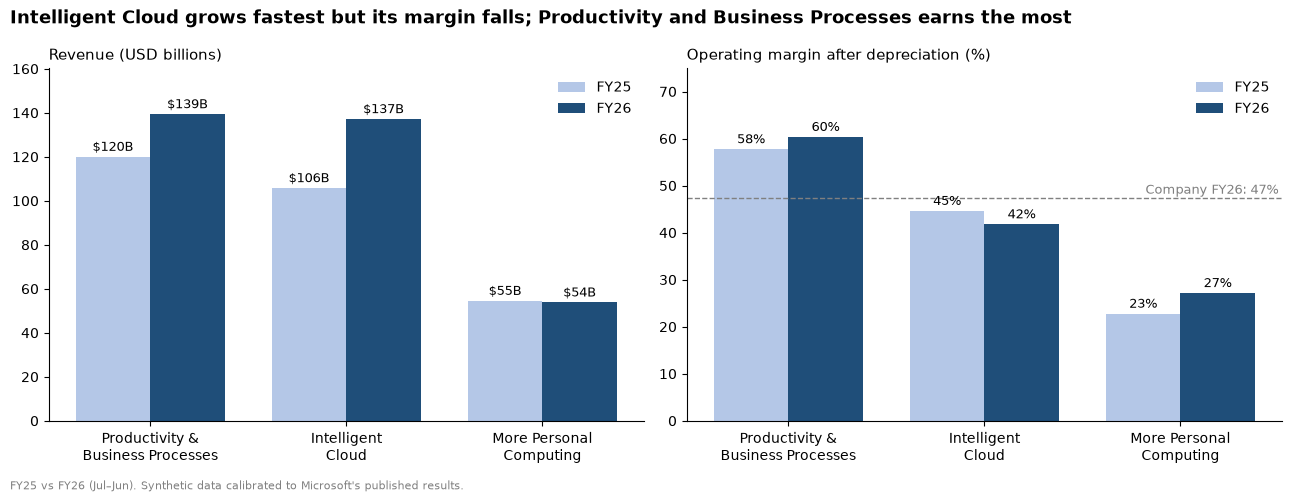

In [4]:
import matplotlib.pyplot as plt

order = seg_fy.index.tolist()
short_names = {"Productivity and Business Processes": "Productivity &\nBusiness Processes",
               "Intelligent Cloud": "Intelligent\nCloud",
               "More Personal Computing": "More Personal\nComputing"}
labels = [short_names.get(s, s) for s in order]
x = range(len(order))
width = 0.38

fig, (ax_rev, ax_margin) = plt.subplots(1, 2, figsize=(13, 4.8))

for i, (fy, color) in enumerate([("fy25", "#B4C7E7"), ("fy26", "#1F4E79")]):
    positions = [p + (i - 0.5) * width for p in x]

    revenue_bn = seg_fy[f"revenue_usd_{fy}"] / 1e9
    bars = ax_rev.bar(positions, revenue_bn, width, color=color, label=fy.upper())
    ax_rev.bar_label(bars, labels=[f"${v:,.0f}B" for v in revenue_bn], fontsize=9, padding=2)

    margin_pct = seg_fy[f"operating_margin_{fy}"] * 100
    bars = ax_margin.bar(positions, margin_pct, width, color=color, label=fy.upper())
    ax_margin.bar_label(bars, labels=[f"{v:.0f}%" for v in margin_pct], fontsize=9, padding=2)

# Company-wide FY26 margin as the reference line (the "high margin" cut-off of the portfolio map)
fy26 = segments[segments["fiscal_year"] == "FY26"]
company_margin = fy26["operating_income_usd"].sum() / fy26["revenue_usd"].sum() * 100
ax_margin.axhline(company_margin, color="grey", linestyle="--", linewidth=1)
ax_margin.text(len(order) - 0.5, company_margin + 1, f"Company FY26: {company_margin:.0f}%",
               ha="right", fontsize=9, color="grey")

for ax, title in [(ax_rev, "Revenue (USD billions)"),
                  (ax_margin, "Operating margin after depreciation (%)")]:
    ax.set_xticks(list(x))
    ax.set_xticklabels(labels)
    ax.set_title(title, loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
ax_rev.set_ylim(0, seg_fy["revenue_usd_fy26"].max() / 1e9 * 1.15)
ax_margin.set_ylim(0, 75)

fig.suptitle("Intelligent Cloud grows fastest but its margin falls; "
             "Productivity and Business Processes earns the most",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.02, "FY25 vs FY26 (Jul–Jun). Synthetic data calibrated to Microsoft's published results.",
         fontsize=8, color="grey")
plt.tight_layout()
plt.show()

What this chart shows: 
Left: revenue by segment, FY25 (light blue) vs FY26 (dark blue). 
Right: operating margin; the dashed line is the company’s FY26 margin (47%). Intelligent Cloud drops from above the line in FY25 to below it in FY26.

**Findings (FY26 vs FY25)**
- **Intelligent Cloud** grows fastest (about +30%, driven by Azure) but its operating margin falls about
  3 points to 42%, below the company's 47%: datacenter depreciation grows faster than revenue.
- **Productivity and Business Processes** is the profit engine: about $139B of revenue at a 60% margin, up
  3 points.
- **More Personal Computing** is flat (about $54B) with the lowest margin (27%), although the margin
  improved about 4 points as costs fell.

Next: the same view one level down, by product line, to see which lines drive these results.

## 2. Where to invest: product lines

Each product line is placed on growth × operating margin (FY26) with the cut-offs fixed in advance:
- **High growth:** above the median growth of the 12 product lines.
- **High margin:** above the company-wide operating margin of FY26.

The quadrant sets the action: **Invest** (high growth, high margin), **Optimise** (high growth, low margin),
**Maintain** (low growth, high margin), **Deprioritise** (low growth, low margin).

In [5]:
ACTION_COLORS = {"Invest": "#1F7A3E", "Optimise": "#E08A00", "Maintain": "#2F5597", "Deprioritise": "#A6A6A6"}

lines = con.sql("""
    SELECT product_line, segment, revenue_usd, operating_income_usd, revenue_growth, operating_margin,
           median_growth, company_margin, portfolio_action
    FROM v_portfolio_fy26
    ORDER BY revenue_usd DESC
""").df()

lines.style.format({
    "revenue_usd": lambda v: f"${v / 1_000_000_000:,.1f}B",
    "operating_income_usd": lambda v: f"${v / 1_000_000_000:,.1f}B",
    "revenue_growth": "{:+.1%}",
    "operating_margin": "{:.1%}",
    "median_growth": "{:.1%}",
    "company_margin": "{:.1%}",
}).hide(axis="index")

product_line,segment,revenue_usd,operating_income_usd,revenue_growth,operating_margin,median_growth,company_margin,portfolio_action
Azure,Intelligent Cloud,$105.7B,$37.4B,+42.6%,35.3%,8.5%,47.3%,Optimise
Microsoft 365 Commercial,Productivity and Business Processes,$96.8B,$61.9B,+17.6%,64.0%,8.5%,47.3%,Invest
Server Products,Intelligent Cloud,$23.7B,$18.0B,-2.1%,76.1%,8.5%,47.3%,Maintain
Gaming,More Personal Computing,$21.9B,$2.2B,-5.7%,10.1%,8.5%,47.3%,Deprioritise
LinkedIn,Productivity and Business Processes,$19.0B,$7.4B,+10.4%,39.0%,8.5%,47.3%,Optimise
Search and News Advertising,More Personal Computing,$15.4B,$4.9B,+11.9%,31.8%,8.5%,47.3%,Optimise
Windows OEM,More Personal Computing,$11.8B,$8.1B,-1.3%,68.9%,8.5%,47.3%,Maintain
Dynamics 365,Productivity and Business Processes,$8.6B,$4.3B,+17.7%,49.5%,8.5%,47.3%,Invest
Microsoft 365 Consumer,Productivity and Business Processes,$8.5B,$5.5B,+19.8%,65.0%,8.5%,47.3%,Invest
Enterprise and Partner Services,Intelligent Cloud,$7.8B,$2.0B,+3.9%,25.7%,8.5%,47.3%,Deprioritise


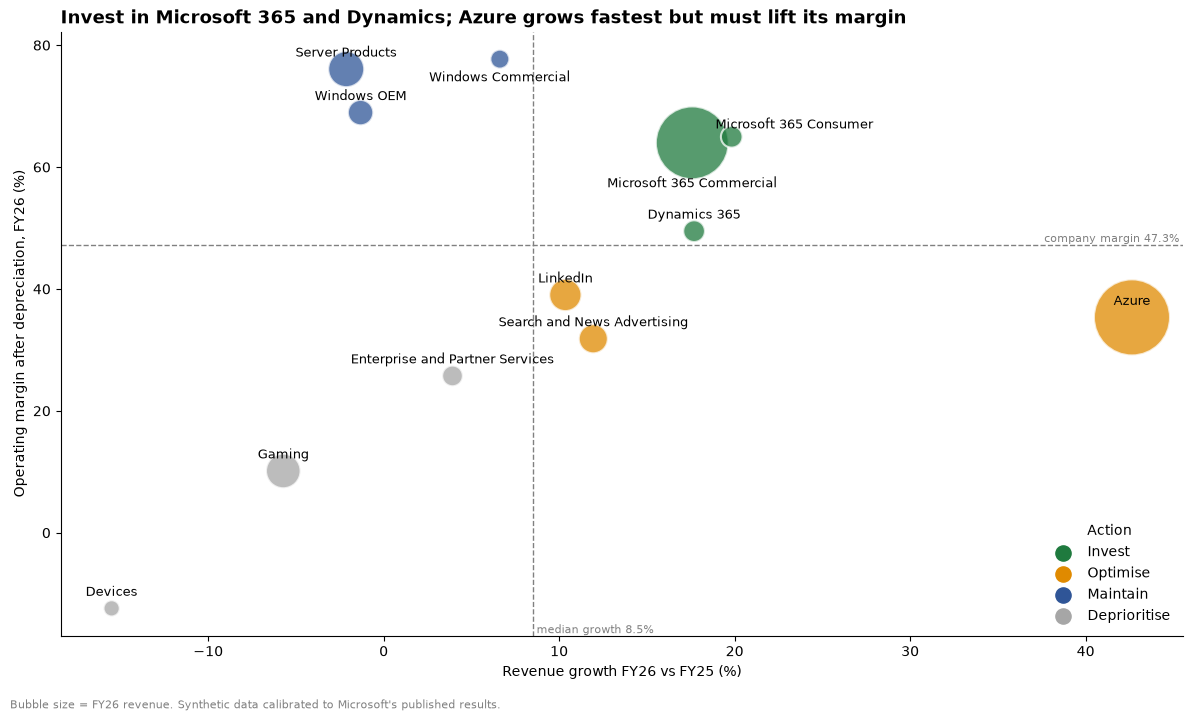

In [6]:
def portfolio_map(df, name_col, title, size_scale=3000, label_size=9, label_offsets=None, ylim=None):
    """Growth x margin scatter: bubble = revenue, colour = action, dashed lines = the two cut-offs."""
    growth_cut = df["median_growth"].iloc[0] * 100
    margin_cut = df["company_margin"].iloc[0] * 100
    fig, ax = plt.subplots(figsize=(12, 7))
    sizes = df["revenue_usd"] / df["revenue_usd"].max() * size_scale
    ax.scatter(df["revenue_growth"] * 100, df["operating_margin"] * 100, s=sizes,
               c=df["portfolio_action"].map(ACTION_COLORS), alpha=0.75, edgecolors="white", linewidths=1.5)
    label_offsets = label_offsets or {}
    for _, row in df.iterrows():
        dx, dy = label_offsets.get(row[name_col], (0, 9))      # move labels that would overlap
        ax.annotate(row[name_col], (row["revenue_growth"] * 100, row["operating_margin"] * 100),
                    xytext=(dx, dy), textcoords="offset points", ha="center", fontsize=label_size)
    if ylim:
        ax.set_ylim(*ylim)
    ax.axvline(growth_cut, color="grey", linestyle="--", linewidth=1)
    ax.axhline(margin_cut, color="grey", linestyle="--", linewidth=1)
    ax.text(growth_cut, ax.get_ylim()[0], f" median growth {growth_cut:.1f}%", va="bottom", fontsize=8, color="grey")
    ax.text(ax.get_xlim()[1], margin_cut, f"company margin {margin_cut:.1f}% ", ha="right", va="bottom",
            fontsize=8, color="grey")
    for action, color in ACTION_COLORS.items():
        ax.scatter([], [], c=color, s=120, label=action)
    ax.legend(title="Action", frameon=False, loc="lower right")
    ax.set_xlabel("Revenue growth FY26 vs FY25 (%)")
    ax.set_ylabel("Operating margin after depreciation, FY26 (%)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold")
    fig.text(0.01, -0.02, "Bubble size = FY26 revenue. Synthetic data calibrated to Microsoft's published results.",
             fontsize=8, color="grey")
    plt.tight_layout()
    return ax


portfolio_map(lines, "product_line",
              "Invest in Microsoft 365 and Dynamics; Azure grows fastest but must lift its margin",
              label_offsets={"Microsoft 365 Commercial": (0, -32), "Microsoft 365 Consumer": (45, 6),
                             "Windows Commercial": (0, -16)})
plt.show()

**Findings (FY26).** Cut-offs: median growth 8.5%, company margin 47.3%.
- **Invest:** Microsoft 365 Commercial (+17.6%, 64% margin, $97B), Dynamics 365 (+17.7%, 50%) and
  Microsoft 365 Consumer (+19.8%, 65%).
- **Optimise:** Azure grows fastest (+42.6%) but its 35% margin is below the company's, because datacenter
  depreciation grows with capacity. LinkedIn (39%) and Search and News Advertising (32%) also grow above the
  median with low margins. Whether Azure's capex pays back is tested in `04_return_on_capex.ipynb`.
- **Maintain:** Server Products (76%), Windows OEM (69%) and Windows Commercial (78%) are cash generators
  with little or no growth.
- **Deprioritise:** Gaming (−5.7%, 10% margin), Enterprise and Partner Services (+3.9%, 26%) and Devices
  (−15.5%, negative margin).

## 3. Where to invest: sales regions

The same framework for geography: 3 sales regions and 10 sales areas, each compared with its peers.
Revenue comes from the billing country. Costs are not booked by customer country, so each product line's
operating margin is applied to that line's revenue in the region: regional margins differ only through
**product mix**.

In [7]:
regions = con.sql("""
    SELECT level, region, revenue_usd, operating_income_usd, revenue_growth, operating_margin,
           median_growth, company_margin, portfolio_action
    FROM v_portfolio_region_fy26
    ORDER BY level DESC, revenue_usd DESC
""").df()

regions.style.format({
    "revenue_usd": lambda v: f"${v / 1_000_000_000:,.1f}B",
    "operating_income_usd": lambda v: f"${v / 1_000_000_000:,.1f}B",
    "revenue_growth": "{:+.1%}",
    "operating_margin": "{:.1%}",
    "median_growth": "{:.1%}",
    "company_margin": "{:.1%}",
}).hide(axis="index")

level,region,revenue_usd,operating_income_usd,revenue_growth,operating_margin,median_growth,company_margin,portfolio_action
Sales region,EMEA,$134.9B,$63.0B,+17.2%,46.7%,17.2%,47.3%,Deprioritise
Sales region,Americas,$119.2B,$57.0B,+19.1%,47.8%,17.2%,47.3%,Invest
Sales region,APAC,$76.4B,$36.2B,+17.0%,47.4%,17.2%,47.3%,Maintain
Sales area,North America,$102.9B,$49.2B,+19.6%,47.8%,17.3%,47.3%,Invest
Sales area,Western Europe,$99.1B,$46.1B,+18.4%,46.6%,17.3%,47.3%,Optimise
Sales area,Greater Asia,$30.1B,$14.9B,+13.7%,49.5%,17.3%,47.3%,Maintain
Sales area,Latin America,$16.2B,$7.8B,+15.6%,48.2%,17.3%,47.3%,Maintain
Sales area,India,$15.7B,$7.1B,+16.8%,45.2%,17.3%,47.3%,Deprioritise
Sales area,ANZ,$15.6B,$7.2B,+23.2%,46.1%,17.3%,47.3%,Optimise
Sales area,Japan,$15.1B,$7.0B,+17.8%,46.7%,17.3%,47.3%,Optimise


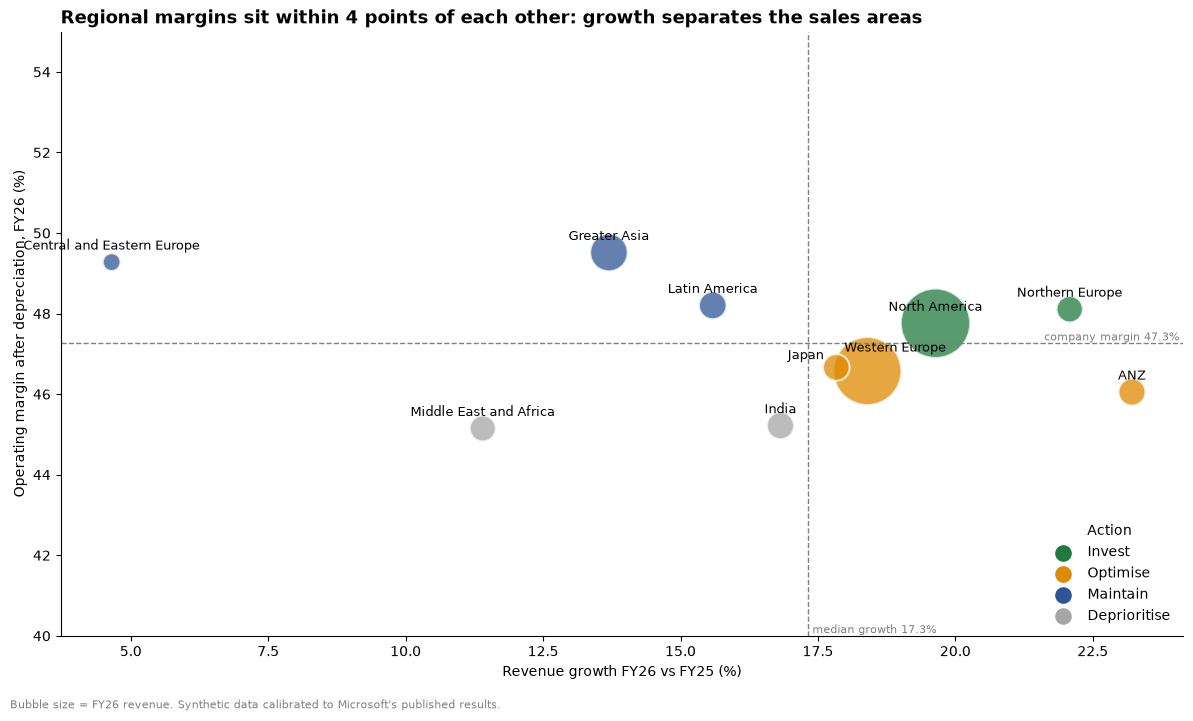

In [8]:
areas = regions[regions["level"] == "Sales area"]
portfolio_map(areas, "region",
              "Regional margins sit within 4 points of each other: growth separates the sales areas",
              size_scale=2500,
              label_offsets={"Japan": (-22, 6), "Western Europe": (20, 14)}, ylim=(40, 55))
plt.show()

**Findings (FY26).**
- Margins range only from 45% to 50%, because they reflect product mix, not regional cost differences.
  Growth is what separates the areas: from +4.7% (Central and Eastern Europe) to +23.2% (ANZ).
- **Invest:** North America (+19.6%, $103B) and Northern Europe (+22.1%).
- **Optimise:** Western Europe, Japan and ANZ grow above the median but sell a lower-margin mix
  (more Azure).
- By sales region: **Americas = Invest**, **APAC = Maintain**, **EMEA = Deprioritise**. EMEA is only
  0.6 points below the margin cut-off, so this label is fragile and should not drive a decision on its own.

## 4. Operating leverage: are costs growing slower than revenue?

Operating expense (R&D + sales and marketing + allocated G&A) growth compared with revenue growth,
FY26 vs FY25. When operating expense grows slower than revenue (or falls faster), margins expand.

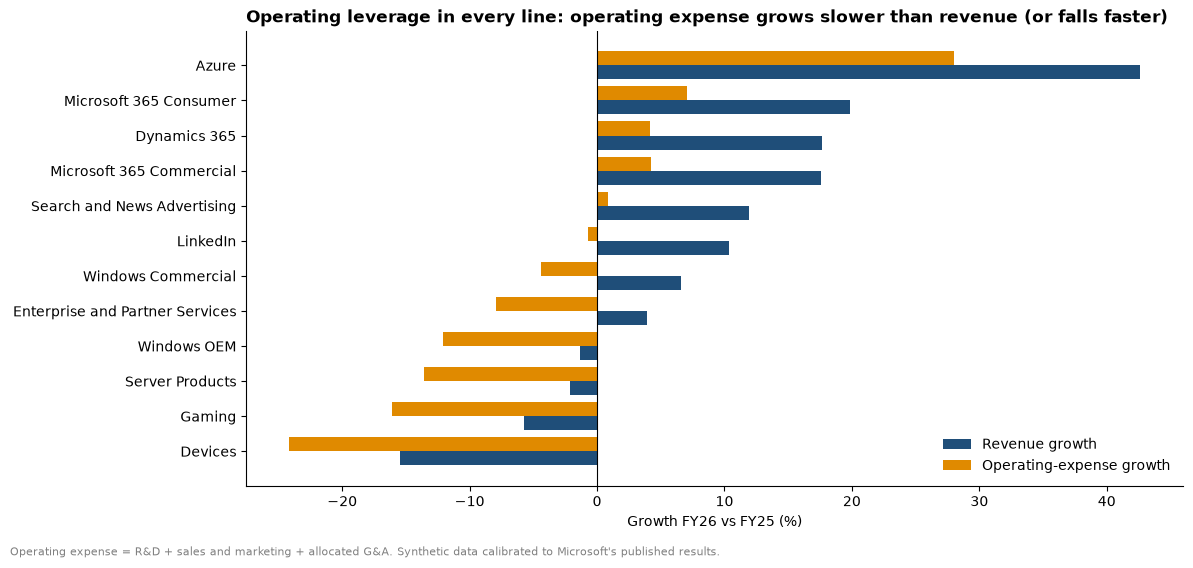

product_line,revenue_growth,opex_growth,gap_pts
Azure,+42.6%,+28.0%,+14.6 pts
Microsoft 365 Consumer,+19.8%,+7.1%,+12.8 pts
Dynamics 365,+17.7%,+4.2%,+13.5 pts
Microsoft 365 Commercial,+17.6%,+4.3%,+13.3 pts
Search and News Advertising,+11.9%,+0.8%,+11.1 pts
LinkedIn,+10.4%,-0.7%,+11.1 pts
Windows Commercial,+6.6%,-4.4%,+11.0 pts
Enterprise and Partner Services,+3.9%,-7.9%,+11.9 pts
Windows OEM,-1.3%,-12.1%,+10.8 pts
Server Products,-2.1%,-13.5%,+11.4 pts


In [9]:
leverage = con.sql("""
    SELECT cur.product_line,
           cur.revenue_usd / prev.revenue_usd - 1                                      AS revenue_growth,
           (cur.rnd_usd + cur.snm_usd + cur.ga_allocated_usd)
             / (prev.rnd_usd + prev.snm_usd + prev.ga_allocated_usd) - 1                AS opex_growth
    FROM v_profitability_fy AS cur
    JOIN v_profitability_fy AS prev
      ON prev.product_line = cur.product_line AND prev.fiscal_year = 'FY25'
    WHERE cur.fiscal_year = 'FY26'
    ORDER BY revenue_growth DESC
""").df()
leverage["gap_pts"] = (leverage["revenue_growth"] - leverage["opex_growth"]) * 100

fig, ax = plt.subplots(figsize=(12, 5.5))
y = range(len(leverage))
ax.barh([p + 0.2 for p in y], leverage["revenue_growth"] * 100, height=0.4, color="#1F4E79", label="Revenue growth")
ax.barh([p - 0.2 for p in y], leverage["opex_growth"] * 100, height=0.4, color="#E08A00",
        label="Operating-expense growth")
ax.set_yticks(list(y))
ax.set_yticklabels(leverage["product_line"])
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Growth FY26 vs FY25 (%)")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Operating leverage in every line: operating expense grows slower than revenue (or falls faster)",
             loc="left", fontsize=12, fontweight="bold")
fig.text(0.01, -0.02, "Operating expense = R&D + sales and marketing + allocated G&A. "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

leverage.style.format({"revenue_growth": "{:+.1%}", "opex_growth": "{:+.1%}",
                       "gap_pts": "{:+.1f} pts"}).hide(axis="index")

**Findings.** Every product line shows operating leverage in FY26, as in Microsoft's published results.
- Growing lines keep operating expense well below revenue growth: Azure +42.6% revenue vs about +28%
  operating expense; Microsoft 365 Commercial and Dynamics 365 about +18% revenue vs about +4–5%.
- Shrinking lines (Devices, Gaming, Server Products, Windows OEM) cut operating expense faster than revenue
  falls, which protects their margins.
- So Azure's lower margin is not an operating-expense problem: it comes from cost of revenue, mainly
  datacenter depreciation (notebook 04).

## 5. Opportunity sizing

Value of each action = revenue affected × realistic improvement × operating margin. "Realistic" = the
median of the better half of peers, not the single best one.
- **Invest:** close the growth gap, valued at the line's own margin.
- **Optimise / Deprioritise:** close the margin gap (pricing, cost of revenue or cost cuts).
- **Maintain:** protect the cash; no value assigned.

In [10]:
sizing = con.sql("""
    SELECT level, entity, portfolio_action, revenue_usd, revenue_growth, operating_margin,
           target_growth, target_margin, opportunity_value_usd, value_rank
    FROM v_opportunity_sizing
    WHERE opportunity_value_usd > 0
    ORDER BY value_rank
""").df()

sizing.style.format({
    "revenue_usd": lambda v: f"${v / 1_000_000_000:,.1f}B",
    "opportunity_value_usd": lambda v: f"${v / 1_000_000_000:,.2f}B",
    "revenue_growth": "{:+.1%}",
    "target_growth": "{:+.1%}",
    "operating_margin": "{:.1%}",
    "target_margin": "{:.1%}",
}).hide(axis="index")

level,entity,portfolio_action,revenue_usd,revenue_growth,operating_margin,target_growth,target_margin,opportunity_value_usd,value_rank
Product line,Azure,Optimise,$105.7B,+42.6%,35.3%,+17.6%,67.0%,$33.42B,1
Product line,Gaming,Deprioritise,$21.9B,-5.7%,10.1%,+17.6%,67.0%,$12.41B,2
Product line,Search and News Advertising,Optimise,$15.4B,+11.9%,31.8%,+17.6%,67.0%,$5.42B,3
Product line,LinkedIn,Optimise,$19.0B,+10.4%,39.0%,+17.6%,67.0%,$5.31B,4
Product line,Devices,Deprioritise,$4.8B,-15.5%,-12.4%,+17.6%,67.0%,$3.82B,5
Product line,Enterprise and Partner Services,Deprioritise,$7.8B,+3.9%,25.7%,+17.6%,67.0%,$3.22B,6
Sales area,Western Europe,Optimise,$99.1B,+18.4%,46.6%,+19.6%,48.2%,$1.61B,7
Sales region,EMEA,Deprioritise,$134.9B,+17.2%,46.7%,+18.2%,47.6%,$1.17B,8
Sales area,India,Deprioritise,$15.7B,+16.8%,45.2%,+19.6%,48.2%,$0.47B,9
Sales area,Middle East and Africa,Deprioritise,$14.4B,+11.4%,45.1%,+19.6%,48.2%,$0.44B,10


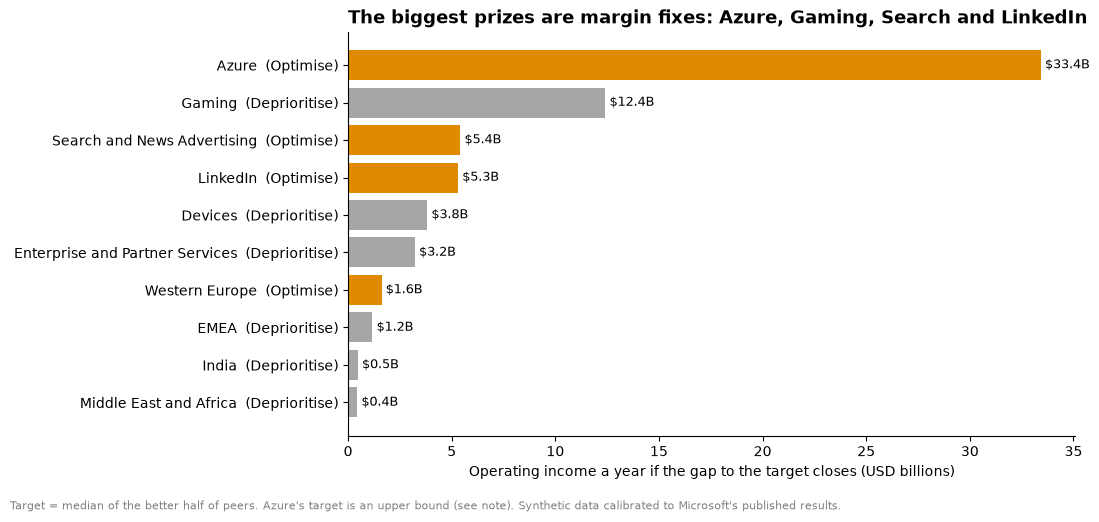

In [11]:
top = sizing.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(top["entity"] + "  (" + top["portfolio_action"] + ")", top["opportunity_value_usd"] / 1e9,
               color=top["portfolio_action"].map(ACTION_COLORS))
ax.bar_label(bars, labels=[f"${v / 1e9:,.1f}B" for v in top["opportunity_value_usd"]], padding=3, fontsize=9)
ax.set_xlabel("Operating income a year if the gap to the target closes (USD billions)")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("The biggest prizes are margin fixes: Azure, Gaming, Search and LinkedIn",
             loc="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.03, "Target = median of the better half of peers. Azure's target is an upper bound (see note). "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

**Findings.**
- **Azure: $33.4B a year, an upper bound.** The target margin (67%) is the median of the better half of all
  product lines, which includes licence businesses (Windows, Server Products) that have no datacenter
  costs. A capital-heavy cloud business will not reach that margin, so treat this as a ceiling; the
  return-on-capex analysis in notebook 04 is the better test for Azure.
- **Gaming: $12.4B** of margin gap: the largest realistic prize, and a Deprioritise line, so the lever is
  cost reduction.
- **Search and News Advertising ($5.4B) and LinkedIn ($5.3B):** pricing and cost-of-revenue fixes.
- Regional opportunities are small (under $2B each) because regional margins differ only through mix.

## Summary

- **Segments:** Intelligent Cloud grows fastest (about +30%) but its margin fell 3 points to 42%;
  Productivity and Business Processes earns 60%; More Personal Computing is flat at 27%.
- **Invest:** Microsoft 365 Commercial, Dynamics 365, Microsoft 365 Consumer; North America and
  Northern Europe.
- **Optimise:** Azure, LinkedIn, Search. Azure's margin gap is a capital question (depreciation), not an
  operating-expense one.
- **Deprioritise:** Gaming, Devices, Enterprise and Partner Services.
- **Next:** `04_return_on_capex.ipynb` tests whether the datacenter capex behind Azure earns its 9% cost
  of capital, region by region.

In [12]:
con.close()   # releases data/finance.duckdb so the next notebook can open it